In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from IPython.display import display, Markdown

# Locate the BirdBase workbook
source_file = Path("BIRDBASE v2025.1 Sekercioglu et al. Final.xlsx")

# Upload the file if it is not already available
if not source_file.exists():
    from google.colab import files
    uploaded = files.upload()

    spreadsheets = [
        name for name in uploaded
        if name.lower().endswith(".xlsx")
    ]

    if not spreadsheets:
        raise FileNotFoundError(
            "Upload the BirdBase .xlsx workbook to continue."
        )

    source_file = Path(spreadsheets[0])

print(f"Using BirdBase source: {source_file.name}")

Using BirdBase source: BIRDBASE v2025.1 Sekercioglu et al. Final.xlsx


### Selecting the Relevant Variables

The BirdBase dataset contains numerous characteristics of bird species, but this analysis focuses only on diet and body mass.

We use the Average Mass column for bird weight and the dietary-weight columns for food composition.

The Excel Data sheet contains its actual field names in the second row, so we specify header=1 when importing.

In [8]:
# Columns representing different food groups
food_columns = [
    "IN-Wt", "FR-Wt", "NE-Wt", "SE-Wt", "VE-Wt",
    "FI-Wt", "SC-Wt", "PL-Wt", "MS-Wt"
]

# Food groups representing plant-based diets
plant_columns = [
    "FR-Wt",
    "NE-Wt",
    "SE-Wt",
    "PL-Wt"
]

# All relevant columns for the analysis
needed_columns = [
    "IOC 15.1",
    "Primary Diet",
    "Average Mass",
    *food_columns,
    "SUM-Wt",
    "Diet_Lit"
]

# Read the Data sheet from BirdBase
raw = pd.read_excel(
    source_file,
    sheet_name="Data",
    header=1,
    usecols=needed_columns,
    engine="openpyxl"
)

# Rename the species identifier column
raw = raw.rename(
    columns={"IOC 15.1": "Species ID"}
)

print(
    f"Imported {len(raw):,} species "
    f"with {len(raw.columns)} relevant fields."
)

# Preview the relevant data
display(
    raw[
        [
            "Species ID",
            "Primary Diet",
            "Average Mass",
            "FR-Wt",
            "PL-Wt",
            "SUM-Wt"
        ]
    ].head()
)

Imported 11,589 species with 14 relevant fields.


,Species ID,Primary Diet,Average Mass,FR-Wt,PL-Wt,SUM-Wt
0,1,Herbivore,114500.0,0,5,10.0
1,6,Herbivore,107875.0,0,5,10.0
2,8,Plant,25250.0,0.06,9.01,10.0
3,14,Plant,21925.0,T,9.4,10.0
4,18,Invertebrate,2602.5,T,T,10.0


## 2. Data Preprocessing

Pearson's correlation coefficient measures the linear relationship between two numerical variables.

However, the Primary Diet column in BirdBase contains categorical labels such as Fruit, Invertebrate, and Omnivore.

Because these categories cannot be meaningfully assigned arbitrary numerical values, we instead use the numeric dietary weights supplied by BirdBase.

**Diet variable:**
Plant-food diet score = FR-Wt + NE-Wt + SE-Wt + PL-Wt

- FR-Wt: Fruit
- NE-Wt: Nectar
- SE-Wt: Seeds
- PL-Wt: Other plant materials

The total dietary score is normally 10 for known diets. A higher plant-food score indicates a larger plant-food component.

**Weight variable:**
Average Mass, measured in grams.

Because bird body masses vary dramatically between species, we apply a log10 transformation to average mass.

We also:
- Convert numeric columns to appropriate data types.
- Treat trace dietary weights marked T as zero scored weight.
- Remove invalid or missing data.
- Keep only published dietary records (Diet_Lit = 1).
- Verify that dietary weights add up correctly.

The resulting analysis will compare plant-food diet score against log10 average mass.

In [9]:
data = raw.copy()

# BirdBase uses 'T' for trace dietary items.
# These contribute zero to the numeric weight score.
for col in food_columns:
    cleaned_text = (
        data[col]
        .astype("string")
        .str.strip()
        .replace({"T": "0", "t": "0"})
    )

    data[col] = pd.to_numeric(
        cleaned_text,
        errors="coerce"
    )

# Convert relevant columns to numeric values
for col in ["Average Mass", "SUM-Wt", "Diet_Lit"]:
    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

# Verify the sum of dietary weights
data["checked_diet_sum"] = data[food_columns].sum(
    axis=1,
    min_count=len(food_columns)
)

# Filter for valid observations
valid_rows = (
    data["Diet_Lit"].eq(1)
    & data["Average Mass"].gt(0)
    & data["SUM-Wt"].gt(0)
    & data[food_columns].notna().all(axis=1)
    & data[food_columns].ge(0).all(axis=1)
    & data[food_columns].le(10).all(axis=1)
    & np.isclose(data["SUM-Wt"], 10, atol=1e-6)
    & np.isclose(
        data["checked_diet_sum"],
        data["SUM-Wt"],
        atol=1e-6
    )
)

#keep only valid rows
analysis = data.loc[valid_rows].copy()

#calculate plant-based diet score
analysis["plant_diet_score"] = (
    analysis[plant_columns].sum(axis=1)
)

#calculate log10 body mass
analysis["log10_mass_g"] = np.log10(
    analysis["Average Mass"]
)

#verify that enough observations exist
if (
    len(analysis) < 3
    or analysis["plant_diet_score"].nunique() < 2
):
    raise ValueError(
        "Too few valid species records for Pearson's correlation."
    )

print(f"Rows in original workbook: {len(raw):,}")

print(
    "Rows retained for Pearson's analysis: "
    f"{len(analysis):,}"
)

print(
    f"Rows excluded: {len(raw) - len(analysis):,}"
)

#preview
display(
    analysis[
        [
            "Species ID",
            "Primary Diet",
            "Average Mass",
            "plant_diet_score",
            "log10_mass_g"
        ]
    ].head(8)
)

Rows in original workbook: 11,589
Rows retained for Pearson's analysis: 9,361
Rows excluded: 2,228


,Species ID,Primary Diet,Average Mass,plant_diet_score,log10_mass_g
0,1,Herbivore,114500.00,8.0,5.058805
1,6,Herbivore,107875.00,8.0,5.032921
2,8,Plant,25250.00,9.96,4.402261
3,14,Plant,21925.00,10.0,4.340940
4,18,Invertebrate,2602.50,0.0,3.415391
5,21,Invertebrate,2602.50,0.0,3.415391
7,24,Invertebrate,1296.50,2.0,3.112773
8,25,Invertebrate,2156.25,2.0,3.333699


## Pearson's Correlation Coefficient

We use Pearson's correlation coefficient to determine whether bird diet and body mass have a statistically significant linear relationship.

Our variables are:

- X: Plant-food diet score (0–10)
- Y: Log10 of average body mass in grams

### Hypotheses

**Null Hypothesis (H0):**
There is no linear correlation between plant-food diet score and log-transformed body mass.

H0: ρ = 0

**Alternative Hypothesis (H1):**
There is a nonzero linear correlation between plant-food diet score and log-transformed body mass.

H1: ρ ≠ 0

### Significance Level

α = 0.05.

If p < 0.05, we reject the null hypothesis.

If p ≥ 0.05, we fail to reject the null hypothesis.

Pearson's r ranges from -1 to +1, where values closer to zero indicate weaker linear relationships.

In [10]:
#two numerical variables
x = analysis["plant_diet_score"].to_numpy(
    dtype=float
)

y = analysis["log10_mass_g"].to_numpy(
    dtype=float
)

#calculate Pearson's correlation coefficient
r, p_value = pearsonr(x, y)

#number of observations
n = len(analysis)

alpha = 0.05

#display
print(
    "Pearson correlation: plant-food diet score "
    "vs log10 average mass"
)

print(f"n                 = {n:,} species")
print(f"Pearson r         = {r:.6f}")
print(f"Two-sided p-value = {p_value:.4g}")

print(
    f"Significance      = "
    f"{'p < 0.05: reject H0' if p_value < alpha else 'p >= 0.05: do not reject H0'}"
)

Pearson correlation: plant-food diet score vs log10 average mass
n                 = 9,361 species
Pearson r         = 0.050293
Two-sided p-value = 1.125e-06
Significance      = p < 0.05: reject H0


## Visualization

We use a scatterplot to visualize the relationship between
plant-food diet score and bird body mass.

- X-axis: Plant-food diet score (0–10)
- Y-axis: Log10 average body mass in grams
- Gray dots: Individual bird species
- Black line: Line of best fit

The transparency of the dots helps display overlapping observations.

The line of best fit helps illustrate the direction of the
linear relationship between the two variables.

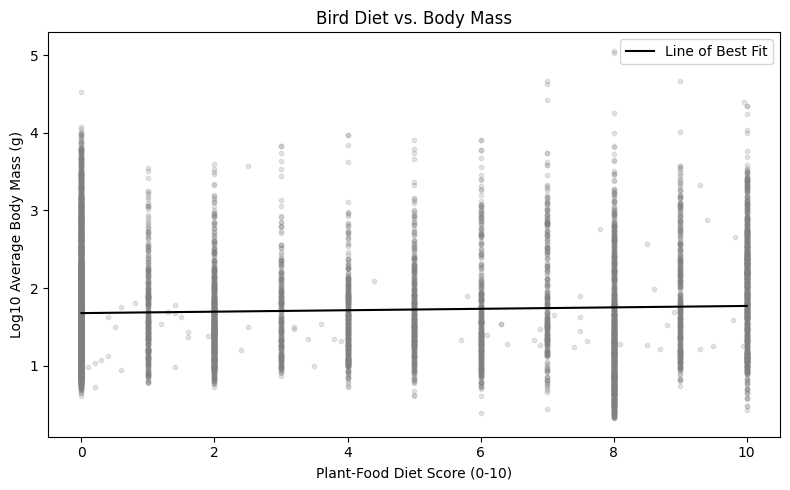

In [14]:
import numpy as np
import matplotlib.pyplot as plt

#select variables from cleaned data
x = analysis["plant_diet_score"]
y = analysis["log10_mass_g"]

#create scatterplot
plt.figure(figsize=(8, 5))

plt.scatter(
    x,
    y,
    color="gray",
    alpha=0.2,
    s=10
)

#calculate line of best fit
slope, intercept = np.polyfit(x, y, 1)

x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

#regression line
plt.plot(
    x_line,
    y_line,
    color="black",
    label="Line of Best Fit"
)

plt.xlabel("Plant-Food Diet Score (0-10)")
plt.ylabel("Log10 Average Body Mass (g)")
plt.title("Bird Diet vs. Body Mass")

plt.legend()
plt.tight_layout()
plt.show()

## Pearson Correlation Conclusion

We interpret the Pearson correlation coefficient and p-value to determine whether the relationship between plant-food diet score and body mass is statistically significant.

This represents one of the three statistical conclusions required for Checkpoint 2.

In [12]:
#strength of correlation
if abs(r) < 0.10:
    magnitude = "negligible (extremely weak)"
elif abs(r) < 0.30:
    magnitude = "weak"
elif abs(r) < 0.50:
    magnitude = "moderate"
else:
    magnitude = "substantial"

#direction
direction = (
    "positive" if r > 0
    else "negative" if r < 0
    else "zero"
)

conclusion = (
    f"**Conclusion — Pearson diet–weight analysis:** "
    f"Among **{n:,}** bird species with published "
    f"dietary data and valid masses, the plant-food "
    f"dietary score has a **{magnitude} {direction} "
    f"linear association** with log10 average body "
    f"mass (**r = {r:.3f}, two-sided p = {p_value:.2e}**). "
)

if p_value < alpha:
    conclusion += (
        "At α = 0.05, we reject the null hypothesis "
        "of zero correlation. However, the coefficient "
        "is close to zero, so this is **not a strong "
        "or practically useful linear relationship** "
        "even though the result is statistically significant."
    )

else:
    conclusion += (
        "At α = 0.05, we do not reject the null "
        "hypothesis of zero correlation. The data "
        "do not provide strong evidence of a linear "
        "relationship under this test."
    )

# Display formatted conclusion
display(Markdown(conclusion))

**Conclusion — Pearson diet–weight analysis:** Among **9,361** bird species with published dietary data and valid masses, the plant-food dietary score has a **negligible (extremely weak) positive linear association** with log10 average body mass (**r = 0.050, two-sided p = 1.13e-06**). At α = 0.05, we reject the null hypothesis of zero correlation. However, the coefficient is close to zero, so this is **not a strong or practically useful linear relationship** even though the result is statistically significant.

### Overall Conclusion

From our pearson correlation analysis, we found that there was a very weak positive correlation between plant-food diet score and log-transformed bird body mass (r ≈ 0.0503). Although the p-value is below our significance level of 0.05 (indicating statistical significance), the correlation coefficient is very close to zero. These findings suggest that there is very little linear relationship between the amount of plant-based food present in a birds diet and the birds body mass. 

Although the positive correlation hints towards birds that have a higher plant-food diet having slightly higher masses, the relationship is still too weak to justify that claim completely. Because of this, we are not able to make meaningful predictions about the body mass of a bird just based purely off of their diet. 

Our statistical significance could be partly due to the fact that we have a large sample size of 9,361 species. Because we have such a large dataset, we could have small correlations that are able to create statistically significant p values. This is the exact reason we can't say that just because we reject the null hypothesis, the variables have a strong relationship with one another.

When analyzing our correlation, we also had to take into account that the body mass of the birds can change due to other factors than just its diet. Things like its location could play a vital role in it's body mass but were not considered when we did our analysis. We only considered the relationship between its plant-food diet score and the body mass.